In [3]:
# If needed, uncomment and run, then restart the kernel:
%pip install numpy pandas scipy matplotlib openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
"""Reproducible per-image apple counting validation.
Install: python -m pip install numpy pandas scipy matplotlib openpyxl
Run: python ny_apple_validation.py
Optional CLI: python ny_apple_validation.py --input workbook.xlsx --output plots
In Jupyter, run the accompanying notebook from top to bottom.
No source values are corrected, trimmed, or excluded as statistical outliers.
"""
from pathlib import Path
import argparse
import hashlib
import json
import platform
import sys
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

INPUT_FILE = Path(r'C:\Users\rs2672\Desktop\YOLO-SAM_automaticAnnotation\NYvalid\NY_Apple_Predicted_vs_Real.xlsx')
OUTPUT_DIR = Path(r'C:\Users\rs2672\Desktop\YOLO-SAM_automaticAnnotation\NYvalid\plots')
DPI = 600
FORMATS = ('png', 'pdf', 'svg')
# These are supplied cultivar/accession labels, not verified botanical species.
LABELS = {
    'rgb_videoblock70': "Rootbag Porter's Perfection",
    'rgb_videoblock_70': "Rootbag Porter's Perfection",
    'rgb_videoFuji2016': 'Fuji',
    'rgb_vodepFuji2016': 'Fuji',
    'rgb_videohoneycrisp': 'Honeycrisp',
    'rgb_videosnapdragon': 'Snapdragon',
    'rgb_videospijon': 'Spijon-pomiferous',
}
COLORS = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00']

In [5]:
def read_counts(path):
    """Locate the image header; ignore workbook formulas and cached summaries."""
    parts = []
    xls = pd.ExcelFile(path, engine='openpyxl')
    for sheet in xls.sheet_names:
        if sheet.lower() == 'summary':
            continue
        if sheet not in LABELS:
            raise ValueError(f'Unmapped worksheet {sheet!r}: add its verified label to LABELS.')
        raw = pd.read_excel(xls, sheet_name=sheet, header=None)
        header = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq('Image filename')]
        if len(header) != 1:
            raise ValueError(f'{sheet}: cannot uniquely locate Image filename header.')
        d = raw.iloc[int(header[0])+1:, :3].copy()
        d.columns = ['image', 'predicted', 'ground_truth']
        d = d.dropna(how='all')
        if d['image'].isna().any():
            raise ValueError(f'{sheet}: count row without an image name.')
        for col in ['predicted', 'ground_truth']:
            d[col] = pd.to_numeric(d[col], errors='raise')
            bad = d[col].isna() | ~np.isfinite(d[col]) | (d[col] < 0) | (d[col] % 1 != 0)
            if bad.any():
                raise ValueError(f'{sheet}: invalid/missing {col} at {d.loc[bad,"image"].tolist()}. Enter nonnegative integers; zero is valid.')
            d[col] = d[col].astype(int)
        d['image'] = d['image'].astype(str).str.strip()
        if d['image'].duplicated().any():
            raise ValueError(f'{sheet}: duplicate image identifiers.')
        d['folder'] = sheet
        d['cultivar'] = LABELS[sheet]
        d['excel_row'] = d.index + 1
        d['frame_number'] = pd.to_numeric(d['image'].str.extract(r'(\d+)(?=\.[^.]+$)', expand=False), errors='coerce')
        d = d.sort_values('frame_number', kind='stable', na_position='last')
        d['sequence_position'] = np.arange(len(d))
        parts.append(d)
    if not parts:
        raise ValueError('No count worksheets found.')
    data = pd.concat(parts, ignore_index=True)
    if data['cultivar'].nunique() != len(parts):
        raise ValueError('Multiple sheets map to one cultivar; check for duplicate datasets.')
    data['error'] = data.predicted - data.ground_truth
    data['absolute_error'] = data.error.abs()
    data['squared_error'] = data.error**2
    data['pair_mean'] = (data.predicted + data.ground_truth)/2
    return data

In [6]:
def metrics(d):
    y = d.ground_truth.to_numpy(dtype=float)
    p = d.predicted.to_numpy(dtype=float)
    e = p-y
    n = len(y)
    sy, sp = y.sum(), p.sum()
    sst = ((y-y.mean())**2).sum()
    varying = n > 1 and np.std(y) > 0 and np.std(p) > 0
    pearson = stats.pearsonr(y,p).statistic if varying else np.nan
    spearman = stats.spearmanr(y,p).statistic if varying else np.nan
    ccc_denom = np.var(y)+np.var(p)+(y.mean()-p.mean())**2
    ccc = 2*np.mean((y-y.mean())*(p-p.mean()))/ccc_denom if ccc_denom else np.nan
    sd = np.std(e,ddof=1) if n > 1 else np.nan
    return dict(n_images=n, total_ground_truth=int(sy), total_predicted=int(sp),
        total_signed_error=int(e.sum()), mae=np.mean(abs(e)), rmse=np.sqrt(np.mean(e**2)),
        median_absolute_error=np.median(abs(e)), p95_absolute_error=np.percentile(abs(e),95),
        max_absolute_error=np.max(abs(e)), mean_bias=e.mean(), sd_error=sd,
        r2=1-np.sum(e**2)/sst if sst else np.nan, pearson_r=pearson,
        spearman_r=spearman, concordance_correlation=ccc,
        wape_percent=100*np.sum(abs(e))/sy if sy else np.nan,
        relative_total_bias_percent=100*(sp-sy)/sy if sy else np.nan,
        predicted_to_real_percent=100*sp/sy if sy else np.nan,
        nrmse_mean_percent=100*np.sqrt(np.mean(e**2))/np.mean(y) if np.mean(y) else np.nan,
        exact_match_percent=100*np.mean(e==0), within_1_percent=100*np.mean(abs(e)<=1),
        within_2_percent=100*np.mean(abs(e)<=2), undercount_percent=100*np.mean(e<0),
        overcount_percent=100*np.mean(e>0), zero_ground_truth_images=int(np.sum(y==0)),
        zero_prediction_images=int(np.sum(p==0)),
        loa_lower=e.mean()-1.96*sd, loa_upper=e.mean()+1.96*sd)


def review_flags(data):
    """Review triggers only; never automatic exclusion or evidence of incorrect GT."""
    flags = []
    for folder,d in data.groupby('folder',sort=False):
        q1,q3 = np.percentile(d.ground_truth,[25,75])
        upper = q3+3*(q3-q1)
        for _,r in d.iterrows():
            reasons=[]
            if r.ground_truth > upper:
                reasons.append('ground truth > Q3 + 3*IQR within folder')
            if r.absolute_error >= 10:
                reasons.append('absolute count error >= 10')
            if reasons:
                flags.append({**r.to_dict(),'review_reason':'; '.join(reasons)})
    return pd.DataFrame(flags, columns=list(data.columns)+['review_reason'])

In [7]:
def configure_style():
    available={f.name for f in font_manager.fontManager.ttflist}
    font=next((f for f in ['Arial','Aptos','Liberation Sans','DejaVu Sans'] if f in available),'DejaVu Sans')
    plt.rcParams.update({'font.family':font,'font.size':10,'axes.titlesize':11,
        'axes.labelsize':10,'axes.spines.top':False,'axes.spines.right':False,
        'axes.linewidth':0.8,'xtick.labelsize':9,'ytick.labelsize':9,
        'legend.fontsize':9,'figure.dpi':120,'savefig.dpi':DPI,
        'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none',
        'axes.axisbelow':True,'savefig.facecolor':'white'})
    return font


def save_figure(fig,name,out):
    for ext in FORMATS:
        fig.savefig(out/f'{name}.{ext}',dpi=DPI,bbox_inches='tight',facecolor='white')
    plt.close(fig)


def panels(title):
    fig,axs=plt.subplots(2,3,figsize=(13.8,8.2),layout='constrained')
    fig.suptitle(title,fontsize=14,fontweight='bold')
    return fig,axs.ravel()


def make_figures(data,summary,out):
    groups=list(data.groupby('cultivar',sort=False))
    palette={name:COLORS[i % len(COLORS)] for i,(name,_) in enumerate(groups)}
    allgroups=groups+[('All cultivars',data)]
    # 1. Full-range parity plots; all observations retained, equal x/y scaling.
    fig,axs=panels('Predicted versus reference apple counts')
    for i,(name,d) in enumerate(allgroups):
        ax=axs[i]; color=palette.get(name,'#334155')
        ax.scatter(d.ground_truth,d.predicted,s=22,alpha=.55,color=color,edgecolors='none')
        limit=max(d.ground_truth.max(),d.predicted.max())*1.06+1
        ax.plot([0,limit],[0,limit],ls='--',lw=1,color='#444444',label='Identity line')
        ax.set(xlim=(-1,limit),ylim=(-1,limit),xlabel='Reference count (apples/image)',ylabel='Predicted count (apples/image)',title=name)
        ax.set_aspect('equal',adjustable='box');m=metrics(d)
        ax.text(.04,.96,f'n = {len(d)}\nMAE = {m["mae"]:.2f}\nRMSE = {m["rmse"]:.2f}\nR² = {m["r2"]:.3f}',transform=ax.transAxes,va='top',fontsize=9)
        ax.grid(alpha=.15)
    save_figure(fig,'01_parity_full_range',out)
    # 2. Main counting metrics, separate scales preserve readability.
    tab=summary.iloc[:-1]; x=np.arange(len(tab))
    fig,axs=plt.subplots(1,3,figsize=(14,4.8),layout='constrained')
    for ax,key,label in zip(axs,['mae','rmse','mean_bias'],['MAE (apples/image)','RMSE (apples/image)','Mean bias: predicted − reference']):
        vals=tab[key].to_numpy();bars=ax.bar(x,vals,color=[palette[n] for n in tab.cultivar],width=.65)
        ax.bar_label(bars,fmt='%.2f',padding=4,fontsize=9);ax.set_ylabel(label)
        ax.set_xticks(x,tab.cultivar,rotation=35,ha='right');ax.axhline(0,color='#555555',lw=.7);ax.margins(y=.22);ax.grid(axis='y',alpha=.15)
    save_figure(fig,'02_error_metrics_by_cultivar',out)
    # 3. Frame-summed totals are not unique-fruit orchard totals.
    fig,ax=plt.subplots(figsize=(10,5.3),layout='constrained')
    b1=ax.bar(x-.19,tab.total_ground_truth,.38,label='Reference',color='#46566B')
    b2=ax.bar(x+.19,tab.total_predicted,.38,label='Predicted',color='#56B4E9')
    ax.bar_label(b1,fmt='%.0f',padding=3);ax.bar_label(b2,fmt='%.0f',padding=3)
    ax.set_xticks(x,tab.cultivar,rotation=20,ha='right');ax.set_ylabel('Sum of per-image counts (includes repeat views)')
    ax.set_title('Predicted and reference counts across evaluated images');ax.legend(frameon=False);ax.margins(y=.18)
    save_figure(fig,'03_frame_summed_counts',out)
    # 4. Empirical cumulative error distribution uses log1p scale, retaining zero.
    fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
    for name,d in groups:
        a=np.sort(d.absolute_error.to_numpy());ax.step(a,np.arange(1,len(a)+1)/len(a),where='post',color=palette[name],lw=1.8,label=name)
    ax.set_xscale('symlog',linthresh=1);ax.set(xlabel='Absolute error (apples/image; symlog scale)',ylabel='Proportion of images',ylim=(0,1.02),title='Cumulative distribution of absolute count error')
    ax.legend(frameon=False,loc='lower right');ax.grid(alpha=.18)
    save_figure(fig,'04_absolute_error_ecdf',out)
    # 5. Bland–Altman: descriptive limits, not confidence intervals.
    fig,axs=panels('Count agreement: Bland–Altman plots')
    for ax,(name,d) in zip(axs,allgroups):
        m=metrics(d);ax.scatter(d.pair_mean,d.error,s=20,alpha=.5,color=palette.get(name,'#334155'),edgecolors='none')
        ax.axhline(0,color='#BBBBBB',lw=.8)
        for value,style,color in [(m['mean_bias'],'-','#333333'),(m['loa_lower'],'--','#A34235'),(m['loa_upper'],'--','#A34235')]:
            ax.axhline(value,ls=style,color=color,lw=1)
        ax.set(title=name,xlabel='Mean of predicted and reference counts',ylabel='Predicted − reference (apples)')
        ax.text(.03,.04,f'Bias {m["mean_bias"]:.2f}; LoA [{m["loa_lower"]:.2f}, {m["loa_upper"]:.2f}]',transform=ax.transAxes,fontsize=8,bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
    save_figure(fig,'05_bland_altman',out)
    # 6. Sequence diagnostics: filenames sorted numerically; no time interval assumed.
    fig,axs=plt.subplots(5,1,figsize=(12,12),layout='constrained')
    for ax,(name,d) in zip(axs,groups):
        ax.plot(d.sequence_position,d.ground_truth,lw=1.2,color='#455468',label='Reference')
        ax.plot(d.sequence_position,d.predicted,lw=1.1,color=palette[name],alpha=.85,label='Predicted')
        ax.set(title=name,ylabel='Apples/image');ax.grid(alpha=.15)
    axs[0].legend(frameon=False,ncol=2);axs[-1].set_xlabel('Image sequence position (numeric filename order; starts at 0)')
    save_figure(fig,'06_image_sequence_counts',out)
    # 7. Exact and near-count agreement, explicitly not detection accuracy.
    fig,ax=plt.subplots(figsize=(10,5.3),layout='constrained')
    for offset,key,label,color in [(-.25,'exact_match_percent','Exact count','#0072B2'),(0,'within_1_percent','Within ±1 apple','#009E73'),(.25,'within_2_percent','Within ±2 apples','#E69F00')]:
        bars=ax.bar(x+offset,tab[key],.25,label=label,color=color);ax.bar_label(bars,fmt='%.1f',padding=2,fontsize=8)
    ax.set_xticks(x,tab.cultivar,rotation=20,ha='right');ax.set(ylim=(0,115),ylabel='Images meeting count-error tolerance (%)',title='Per-image counting agreement');ax.legend(frameon=False,ncol=3)
    save_figure(fig,'07_count_tolerance_agreement',out)
    # 8. Count-dependent error, with observed bins and sample sizes.
    bins=pd.cut(data.ground_truth,[-.5,5,10,20,40,np.inf],labels=['0–5','6–10','11–20','21–40','≥41'])
    rows=[]
    for label in bins.cat.categories:
        d=data.loc[bins==label]
        if len(d): rows.append({'reference_count_bin':label,**metrics(d)})
    density=pd.DataFrame(rows);density.to_csv(out/'metrics_by_reference_count_bin.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(10,4.2),layout='constrained')
    for ax,key in zip(axs,['mae','rmse']):
        bars=ax.bar(density.reference_count_bin,density[key],color='#0072B2')
        ax.bar_label(bars,labels=[f'{v:.2f}\nn={n}' for v,n in zip(density[key],density.n_images)],padding=3,fontsize=9)
        ax.set(xlabel='Reference apples per image',ylabel=key.upper()+' (apples/image)');ax.margins(y=.3)
    save_figure(fig,'08_error_by_reference_count',out)

In [8]:
def run_analysis(input_file=INPUT_FILE,output_dir=OUTPUT_DIR):
    input_file=Path(input_file);out=Path(output_dir)
    if not input_file.is_file():
        raise FileNotFoundError(f'Workbook not found: {input_file}. Update INPUT_FILE or pass --input.')
    out.mkdir(parents=True,exist_ok=True)
    data=read_counts(input_file)
    summary=pd.DataFrame([{'cultivar':name,**metrics(d)} for name,d in data.groupby('cultivar',sort=False)]+[{'cultivar':'All cultivars (pooled)',**metrics(data)}])
    flags=review_flags(data)
    data.to_csv(out/'per_image_results.csv',index=False)
    summary.to_csv(out/'metrics_by_cultivar_and_pooled.csv',index=False)
    flags.to_csv(out/'data_review_flags.csv',index=False)
    data.nlargest(25,'absolute_error').to_csv(out/'largest_25_count_errors.csv',index=False)
    # Unweighted cultivar means are separate from pooled image-weighted results.
    summary.iloc[:-1].select_dtypes(include='number')[['mae','rmse','mean_bias','r2','concordance_correlation','wape_percent']].mean().rename('unweighted_cultivar_mean').to_csv(out/'macro_average_metrics.csv')
    font=configure_style();make_figures(data,summary,out)
    m=metrics(data)
    lines=['# New York apple counting validation',
        f'Analyzed {len(data):,} complete image pairs in {data.cultivar.nunique()} cultivar/accession groups.',
        f'Frame-summed reference count: {m["total_ground_truth"]:,}; predicted count: {m["total_predicted"]:,}.',
        f'Pooled MAE = {m["mae"]:.4f}, RMSE = {m["rmse"]:.4f}, and mean signed bias = {m["mean_bias"]:.4f} apples/image.',
        f'R² = {m["r2"]:.4f}; concordance correlation = {m["concordance_correlation"]:.4f}; WAPE = {m["wape_percent"]:.2f}%.',
        f'Exact count agreement = {m["exact_match_percent"]:.2f}%; within ±1 apple = {m["within_1_percent"]:.2f}%; within ±2 = {m["within_2_percent"]:.2f}%.',
        '\n## Cultivar results']
    for _,r in summary.iloc[:-1].iterrows():
        lines.append(f'- {r.cultivar}: n={r.n_images}; MAE {r.mae:.3f}; RMSE {r.rmse:.3f}; bias {r.mean_bias:.3f}; R² {r.r2:.3f}.')
    lines += ['\n## Data review (no values changed or removed)',f'{len(flags)} records meet a review trigger. Check data_review_flags.csv against original images/count records.']
    for _,r in flags.iterrows():
        lines.append(f'- {r.folder}/{r.image}, Excel row {r.excel_row}: predicted {r.predicted}, reference {r.ground_truth}; {r.review_reason}.')
    lines += ['\n## Interpretation and discussion boundaries',
        '- Primary comparisons are paired per-image counts. Video frames can show the same apples repeatedly; totals are not unique orchard yields.',
        '- Positive bias is overcounting; negative bias is undercounting. RMSE emphasizes large errors; compare it with MAE and median absolute error.',
        '- R² is 1 − SSE/SST using predictions directly, not squared Pearson correlation. It can be negative. Pearson/Spearman association alone does not establish agreement.',
        '- WAPE is 100 × sum absolute errors / sum reference counts. Predicted-to-real percentage is a count ratio, not detection recall or accuracy.',
        '- Bland–Altman limits are descriptive bias ± 1.96 sample SD, not confidence intervals; skewness, heteroscedasticity and dependent frames limit their interpretation.',
        '- No p-values or inferential confidence intervals are reported: tree, video and orchard sampling-unit identifiers are unavailable. Frames must not be treated as independent orchard replicates.',
        '- Cultivar comparisons are descriptive and may be confounded by orchard conditions, occlusion, lighting, image density and repeated viewpoints.',
        '- Count agreement cannot establish precision, recall, F1, mAP, Dice or IoU. Those require matched object-level or pixel-level references.',
        '- These data can support external counting validation of a synthetic-trained model, conditional on confirmed training/test separation. They do not independently prove the training provenance or eliminate the need for field validation.',
        '- Use the claim “no task-specific field imaging or manual annotation for training” only if the full training and annotation pipeline supports it, including any pretrained components.',
        '- The supplied cultivar/accession names are retained. Rootbag is part of the supplied label; no botanical species or horticultural synonym has been inferred.',
        '\n## Figure guide',
        '01 parity; 02 cultivar errors; 03 frame-summed totals; 04 absolute-error ECDF; 05 Bland–Altman; 06 sequence diagnostics; 07 count tolerance; 08 reference-density errors.',
        'All plots retain all observations and are saved as 600-dpi PNG plus vector PDF and SVG. No automatic outlier exclusion or correction is performed.',
        '\n## Metric definitions',
        'error = predicted − reference; MAE = mean(abs(error)); RMSE = sqrt(mean(error²)); bias = mean(error).',
        'CCC = 2 cov(reference,predicted) / [var(reference)+var(predicted)+(mean(reference)−mean(predicted))²], with population moments.',
        'NRMSE(mean) = 100 × RMSE / mean(reference). Undefined quantities are NaN, never replaced by zero.',
        'Pooled metrics use all image pairs; macro averages weight each cultivar equally. Mean cultivar RMSE is not pooled RMSE.']
    (out/'validation_summary.md').write_text('\n\n'.join(lines),encoding='utf-8')
    metadata={'input_file':str(input_file.resolve()),'input_sha256':hashlib.sha256(input_file.read_bytes()).hexdigest(),
        'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
        'matplotlib':matplotlib.__version__,'font_used':font,'dpi':DPI,'formats':FORMATS,'labels':LABELS,
        'n_images':len(data),'review_flag_count':len(flags),'exclusions':0,
        'analysis_unit':'image; adjacent video frames may be correlated'}
    (out/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
    print(summary[['cultivar','n_images','mae','rmse','mean_bias','r2']].to_string(index=False))
    if len(flags): warnings.warn(f'{len(flags)} records flagged for review; all retained. See data_review_flags.csv.')
    print(f'\nSaved all results and figures to: {out.resolve()}')
    return data,summary,flags

In [9]:
data, summary, review = run_analysis(INPUT_FILE, OUTPUT_DIR)
display(summary.round(4))
display(review)

                   cultivar  n_images      mae      rmse  mean_bias       r2
Rootbag Porter's Perfection       191 2.921466 14.747082  -2.722513 0.154858
                       Fuji       190 1.210526  1.657519  -0.905263 0.947361
                 Honeycrisp       162 0.592593  1.024394  -0.518519 0.950445
                 Snapdragon       195 0.605128  1.086042  -0.482051 0.942424
          Spijon-pomiferous       181 0.397790  0.779573  -0.320442 0.947604
     All cultivars (pooled)       919 1.168662  6.806033  -1.009793 0.541765

Saved all results and figures to: C:\Users\rs2672\Desktop\YOLO-SAM_automaticAnnotation\NYvalid\plots


C:\Users\rs2672\AppData\Local\Temp\ipykernel_36388\2106312766.py:57: UserWarning: 1 records flagged for review; all retained. See data_review_flags.csv.
  if len(flags): warnings.warn(f'{len(flags)} records flagged for review; all retained. See data_review_flags.csv.')


,cultivar,n_images,total_ground_truth,total_predicted,total_signed_error,mae,rmse,median_absolute_error,p95_absolute_error,max_absolute_error,...,nrmse_mean_percent,exact_match_percent,within_1_percent,within_2_percent,undercount_percent,overcount_percent,zero_ground_truth_images,zero_prediction_images,loa_lower,loa_upper
0,Rootbag Porter's Perfection,191,4030,3510,-520,2.9215,14.7471,1.0,5.5,201.0,...,69.8931,14.1361,51.3089,72.7749,77.4869,8.3770,0,0,-31.2046,25.7596
1,Fuji,190,2986,2814,-172,1.2105,1.6575,1.0,3.0,7.0,...,10.5468,28.4211,68.4211,87.8947,57.8947,13.6842,0,0,-3.6339,1.8233
2,Honeycrisp,162,1413,1329,-84,0.5926,1.0244,0.0,2.0,5.0,...,11.7446,54.9383,91.9753,95.6790,41.3580,3.7037,2,2,-2.2555,1.2185
3,Snapdragon,195,1855,1761,-94,0.6051,1.0860,0.0,2.0,4.0,...,11.4166,58.9744,87.1795,95.8974,35.8974,5.1282,3,3,-2.3944,1.4303
4,Spijon-pomiferous,181,1390,1332,-58,0.3978,0.7796,0.0,1.0,4.0,...,10.1513,66.2983,97.2376,97.7901,29.8343,3.8674,0,0,-1.7172,1.0763
5,All cultivars (pooled),919,11674,10746,-928,1.1687,6.8060,1.0,3.0,201.0,...,53.5784,44.0696,78.6725,89.7715,48.8575,7.0729,5,5,-14.2092,12.1896


,image,predicted,ground_truth,folder,cultivar,excel_row,frame_number,sequence_position,error,absolute_error,squared_error,pair_mean,review_reason
0,image18.jpg,21,222,rgb_videoblock70,Rootbag Porter's Perfection,29,18,18,-201,201,40401,121.5,ground truth > Q3 + 3*IQR within folder; absol...


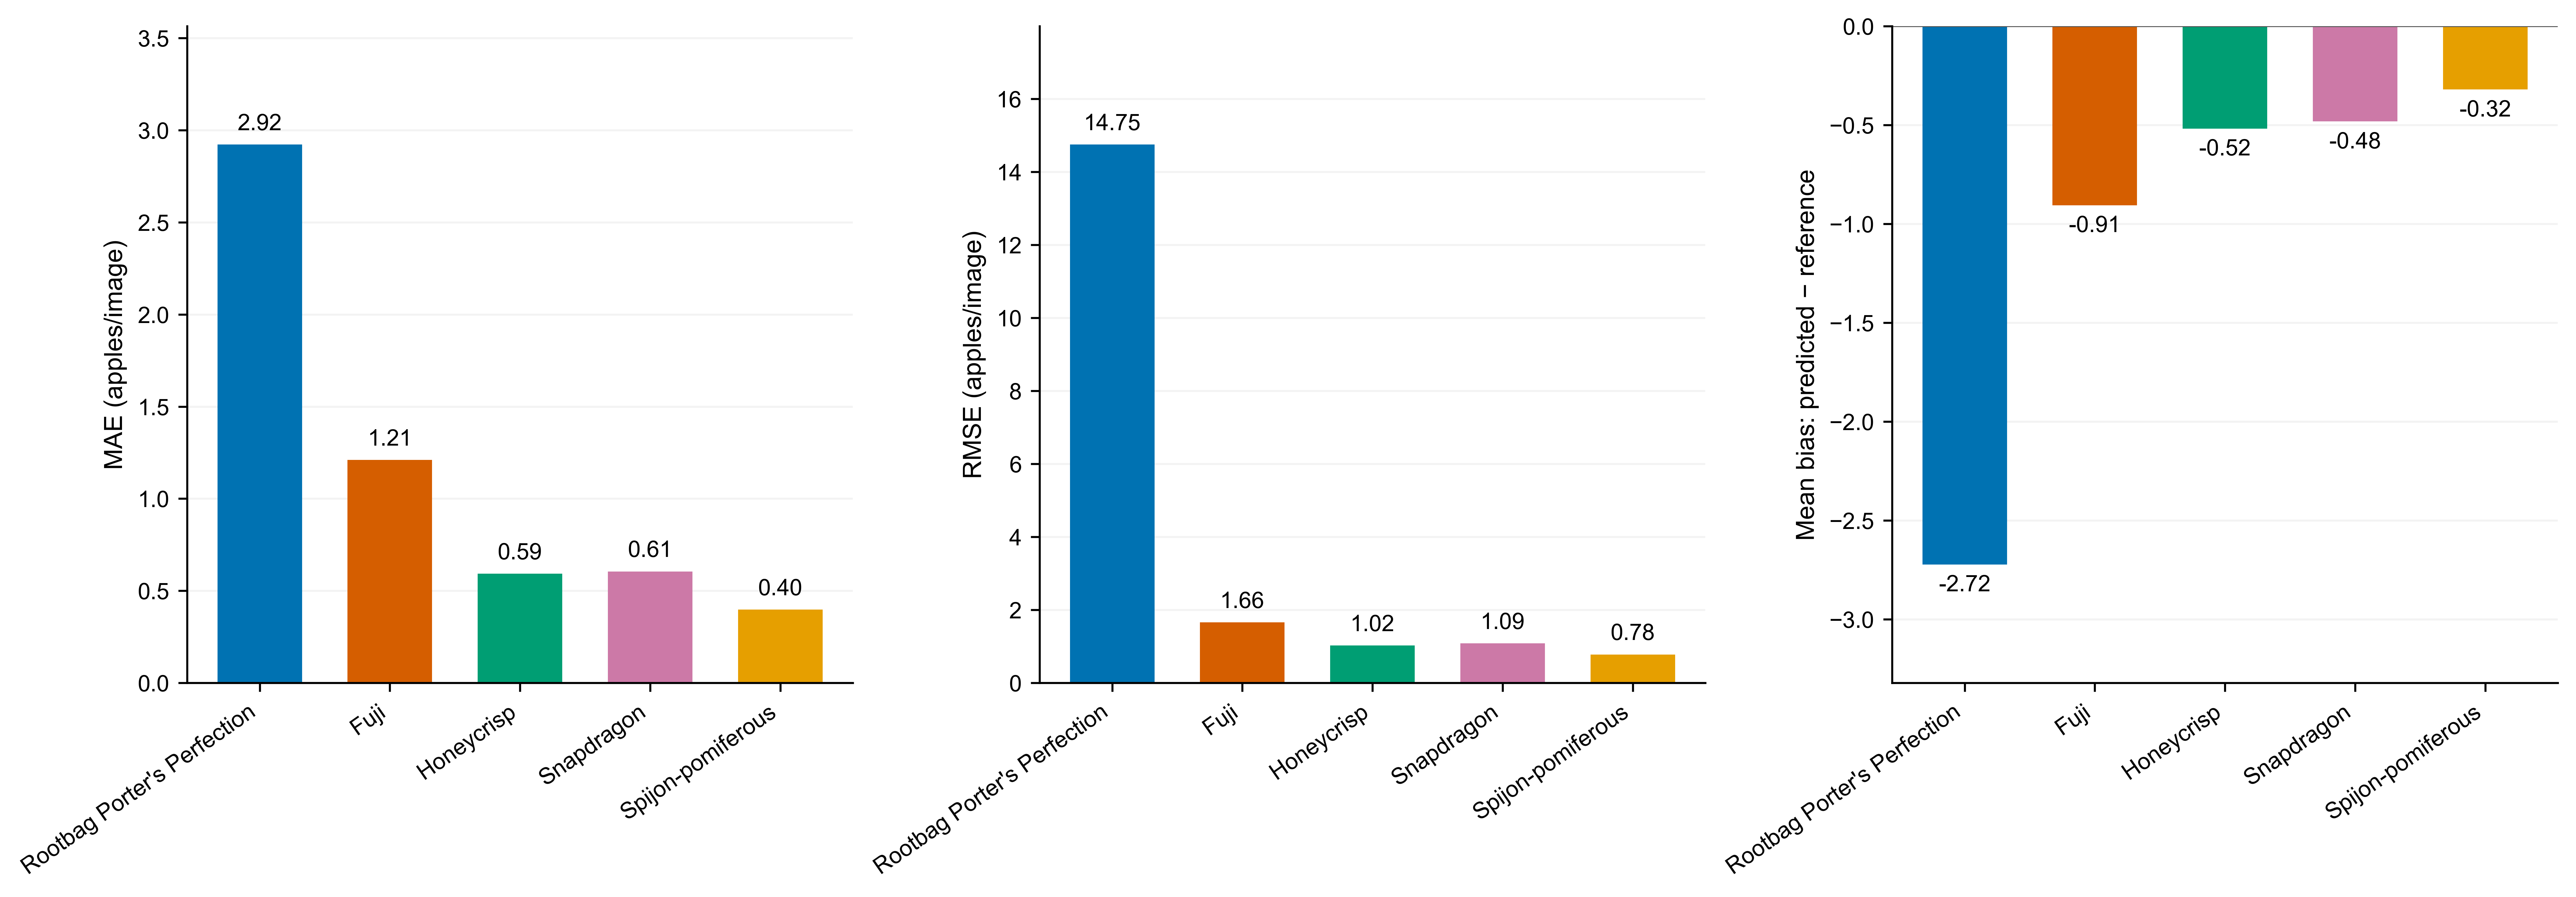

In [10]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / "02_error_metrics_by_cultivar.png"), width=1100))